# Занятие 1. Введение в биометрические системы. Подготовка среды

**Цель работы:** Познакомиться с базовыми понятиями биометрии и подготовить программное окружение для всех последующих лабораторных работ курса.

## Краткие теоретические сведения

**Биометрия** — распознавание человека по физиологическим (лицо, отпечаток пальца, радужка) или поведенческим (голос, походка, почерк) признакам.

**Два режима работы системы:**
- `identification` (1:N, «кто это?»)
- `verification` (1:1, «это действительно он?»)

**Жизненный цикл:**
> enrollment (регистрация шаблона) → capture (захват) → feature extraction (извлечение признаков) → matching (сравнение) → decision (решение)

**Основные метрики качества:** FAR (False Acceptance Rate), FRR (False Rejection Rate), EER (Equal Error Rate) — подробно изучаются в занятии 10.

## Шаг 1–3. Проверка установленных библиотек

In [1]:
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import skimage
import os

print('=' * 50)
print('Проверка установленных библиотек')
print('=' * 50)
print(f'OpenCV version:       {cv2.__version__}')
print(f'NumPy version:        {np.__version__}')
print(f'Matplotlib version:   {matplotlib.__version__}')
print(f'scikit-image version: {skimage.__version__}')
print(f'Python version:       {__import__("sys").version}')
print('=' * 50)

Проверка установленных библиотек
OpenCV version:       5.0.0
NumPy version:        2.2.6
Matplotlib version:   3.10.9
scikit-image version: 0.25.2
Python version:       3.10.7 (tags/v3.10.7:6cc6b13, Sep  5 2022, 14:08:36) [MSC v.1933 64 bit (AMD64)]


## Шаг 4. Проверка веб-камеры

Кадр успешно сохранён в ../reports/camera_test.jpg
Размер кадра: 640x480 пикселей


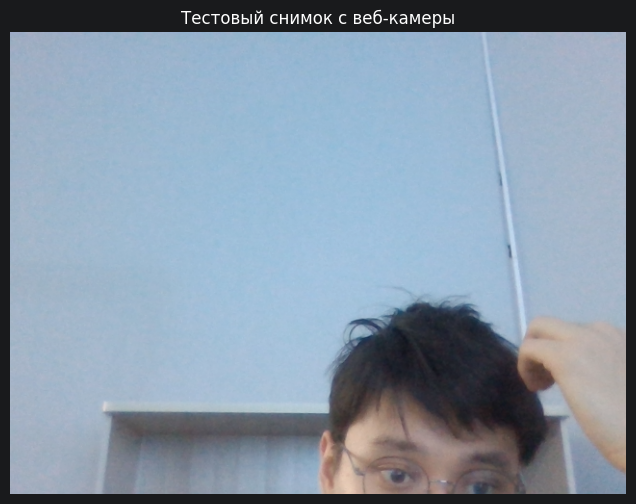

In [2]:
os.makedirs('../reports', exist_ok=True)

cap = cv2.VideoCapture(0)
if not cap.isOpened():
    print('Камера не найдена')
else:
    ret, frame = cap.read()
    if ret:
        output_path = '../reports/camera_test.jpg'
        cv2.imwrite(output_path, frame)
        print(f'Кадр успешно сохранён в {output_path}')
        print(f'Размер кадра: {frame.shape[1]}x{frame.shape[0]} пикселей')
        # Показать в ноутбуке (конвертируем BGR -> RGB)
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(8, 6))
        plt.imshow(frame_rgb)
        plt.title('Тестовый снимок с веб-камеры')
        plt.axis('off')
        plt.savefig('../reports/camera_test_display.png', dpi=100, bbox_inches='tight')
        plt.show()
    else:
        print('Не удалось получить кадр с камеры')
    cap.release()

## Практическое задание 3. Сравнительная таблица биометрических модальностей

| Модальность | Уникальность | Стабильность во времени | Стоимость сенсора | Устойчивость к подделке |
|-------------|--------------|------------------------|-------------------|------------------------|
| **Лицо** | Средняя | Средняя (меняется с возрастом, на внешний вид влияет макияж, борода) | Низкая (обычная камера) | Низкая (фото, 3D-маска) |
| **Отпечаток пальца** | Высокая | Высокая (практически не меняется всю жизнь) | Низкая–Средняя | Средняя (латексный муляж) |
| **Голос** | Низкая | Низкая (меняется при болезни, стрессе, возрасте) | Очень низкая (микрофон) | Низкая (запись, синтез речи) |
| **Радужка глаза** | Очень высокая | Очень высокая (стабильна с рождения) | Высокая (NIR-камера) | Высокая (сложно воспроизвести рисунок) |

> **Вывод:** Наиболее устойчивой к подделке оказалась **радужка глаза**, поскольку её сложный трабекулярный рисунок уникален для каждого человека, формируется случайно в период эмбриогенеза и практически не меняется в течение жизни. Для её сканирования требуется специализированная NIR-камера и активная освещённость, что делает имитацию технически трудновыполнимой.

## Контрольные вопросы

### 1. Чем identification отличается от verification?

**Identification (идентификация, 1:N)** — система должна определить, *кто* перед ней находится, сравнивая биометрический образец со *всеми* шаблонами в базе данных. Ответ: «Это Иванов».

**Verification (верификация, 1:1)** — система должна подтвердить или опровергнуть заявленную личность, сравнивая образец только с *одним конкретным* шаблоном. Ответ: «Да, это действительно Иванов» или «Нет».

Главное различие: verification быстрее и точнее (меньше ложных совпадений), но требует, чтобы пользователь сам сообщил свою личность (например, ввёл ID).

---

### 2. Из каких этапов состоит типовой pipeline биометрической системы?

1. **Enrollment (регистрация)** — пользователь регистрируется в системе: с него снимается биометрический образец и создаётся шаблон, который сохраняется в БД.
2. **Capture (захват)** — при каждом обращении сенсор считывает биометрический признак пользователя.
3. **Feature Extraction (извлечение признаков)** — из «сырых» данных (изображение, аудио) извлекается числовое представление (дескриптор, вектор признаков).
4. **Matching (сравнение)** — полученный вектор сравнивается с шаблоном(и) из базы, вычисляется метрика схожести (score).
5. **Decision (решение)** — на основе score и порога (threshold) система принимает решение: принять или отклонить.

---

### 3. Какая модальность оказалась наиболее устойчивой к подделке и почему?

**Радужка глаза** — наиболее устойчива к подделке по следующим причинам:
- Рисунок радужки формируется случайно в период эмбрионального развития и уникален даже у однояйцевых близнецов.
- Радужка практически не меняется на протяжении всей жизни (в отличие от лица или голоса).
- Современные системы используют инфракрасное (NIR) освещение и анализ реакции зрачка на свет (liveness detection), что делает использование распечатанных фото или контактных линз неэффективным.
- Геометрия глаза трёхмерна и находится за роговицей, что исключает простое копирование.

## Шаг 5. Структура проекта

```
biometrics_env/
├── datasets/       # Наборы данных для экспериментов
├── notebooks/      # Jupyter-ноутбуки (текущая папка)
├── src/            # Исходный код (скрипты Python)
│   └── test_environment.py
├── reports/        # Результаты, скриншоты, отчёты
│   └── camera_test.jpg
└── pyvenv.cfg      # Конфигурация виртуального окружения
```